# Notebook 01: Comprehensive Data Profiling & Exploratory Data Analysis (Module 1)
**Project 02 — Enterprise Predictive Intelligence & Applied Machine Learning System**

This notebook loads all raw datasets from `data/raw/` (using automatic path resolution so it executes cleanly from either the repository root or `notebooks/`), performs schema & integrity checks, quantifies numerical distributions and IQR outliers, and audits cross-column anomalies.


In [1]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
from scipy import stats

DATA_RAW = Path("data/raw") if Path("data/raw").exists() else Path("../data/raw")
DATA_PROC = Path("data/processed") if Path("data/processed").exists() else Path("../data/processed")

datasets = {
    "customer_retention": pd.read_csv(DATA_RAW / "customer_retention_features.csv"),
    "delivery_delay": pd.read_csv(DATA_RAW / "delivery_delay_training.csv"),
    "daily_demand": pd.read_csv(DATA_RAW / "daily_product_demand.csv"),
    "review_train": pd.read_csv(DATA_RAW / "review_sentiment_training.csv"),
    "review_unlabeled": pd.read_csv(DATA_RAW / "review_sentiment_unlabeled.csv"),
    "monitoring_drift": pd.read_csv(DATA_RAW / "model_monitoring_drift_sample.csv"),
    "olist_mql": pd.read_csv(DATA_RAW / "olist_marketing_qualified_leads_dataset.csv"),
    "olist_closed": pd.read_csv(DATA_RAW / "olist_closed_deals_dataset.csv"),
}

inv_rows = []
for name, df in datasets.items():
    inv_rows.append({
        "dataset": name,
        "rows": df.shape[0],
        "cols": df.shape[1],
        "missing_cells": int(df.isnull().sum().sum()),
        "exact_dupes": int(df.duplicated().sum()),
        "memory_mb": round(df.memory_usage(deep=True).sum() / (1024**2), 2)
    })
print("=== DATASET INVENTORY & INTEGRITY SUMMARY ===")
print(pd.DataFrame(inv_rows).to_string(index=False))


=== DATASET INVENTORY & INTEGRITY SUMMARY ===
           dataset   rows  cols  missing_cells  exact_dupes  memory_mb
customer_retention  30000    12              0            0       6.24
    delivery_delay  40000    12              0            0      10.17
      daily_demand 109500     6              0            0      17.54
      review_train  20000     5              0            0       7.07
  review_unlabeled   2000     4              0            0       0.59
  monitoring_drift     80     4              0            0       0.01
         olist_mql   8000     4             60            0       2.01
      olist_closed    842    14              0            0       0.54


## 1. Detailed Numerical Distribution & Skewness/Outlier Profiling
We compute quantiles (`1%`, `25%`, `50%`, `75%`, `99%`), skewness, kurtosis, and Tukey $1.5 \times \text{IQR}$ outlier counts across `customer_retention_features.csv` and `delivery_delay_training.csv`.


In [2]:
def profile_numeric(df, name):
    num_cols = df.select_dtypes(include=[np.number]).columns
    desc = df[num_cols].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).T[["mean", "std", "min", "25%", "50%", "75%", "max"]]
    desc["skew"] = df[num_cols].skew()
    desc["kurt"] = df[num_cols].kurtosis()
    q25, q75 = df[num_cols].quantile(0.25), df[num_cols].quantile(0.75)
    iqr = q75 - q25
    desc["iqr_outliers"] = (((df[num_cols] < (q25 - 1.5 * iqr)) | (df[num_cols] > (q75 + 1.5 * iqr))).sum())
    print(f"\n=== NUMERICAL PROFILE: {name} ===")
    print(desc.round(3).to_string())

profile_numeric(datasets["customer_retention"], "customer_retention_features.csv")
profile_numeric(datasets["delivery_delay"], "delivery_delay_training.csv")


=== NUMERICAL PROFILE: customer_retention_features.csv ===
                             mean     std   min     25%     50%      75%     max   skew    kurt  iqr_outliers
tenure_months              30.572  17.330  1.00  16.000  31.000   46.000   60.00 -0.007  -1.201             0
orders_last_180d            3.850   2.916  0.00   1.000   3.000    6.000   21.00  0.721   0.137            80
avg_order_value            82.474  59.840  5.68  43.110  66.640  103.630  976.74  2.565  13.029          1504
days_since_last_order      89.969  52.252  0.00  45.000  90.000  135.000  180.00 -0.005  -1.196             0
discount_order_share        0.326   0.188  0.00   0.164   0.327    0.489    0.65 -0.002  -1.201             0
returns_last_180d           0.348   0.590  0.00   0.000   0.000    1.000    5.00  1.710   3.044           169
support_tickets_last_180d   1.197   1.094  0.00   0.000   1.000    2.000    8.00  0.891   0.721            42
sessions_last_30d           5.014   2.252  0.00   3.000   5.0

## 2. Programmatic Audit of Logical & Structural Anomalies
We audit cross-feature logical inconsistencies in customer retention, negative delivery durations in delivery delay, template duplication in NLP reviews, and post-conversion nulls in the marketing funnel.


1. Customer Retention Logical Anomalies:
   - days_since_last_order <= 180 but orders_last_180d == 0: 3493
   - returns_last_180d > orders_last_180d: 1261
   - orders_last_180d == 0 but returns_last_180d > 0: 1039

2. Delivery Delay Physical Anomalies:
   - actual_delivery_days < 0: 153 (min = -3.1d)
   - actual_delivery_days <= 0: 178
   - Grace buffer rows (0 < delay_days <= 1.0 yet late_delivery == 0): 6867

3. NLP Review Template Collapse:
   - Unique sentences in 20,000 train rows: 12
   - Unique sentences in 2,000 unlabeled rows: 12
   - Exact template overlap: 12

4. Marketing Funnel Missingness & Conversion:
   - Total MQLs: 8000 | Converted (won_date not null): 842 (10.53%)
   - Missing origin values in MQL table: 60
   - Structural nulls in closed_deals columns for unconverted leads: 7158


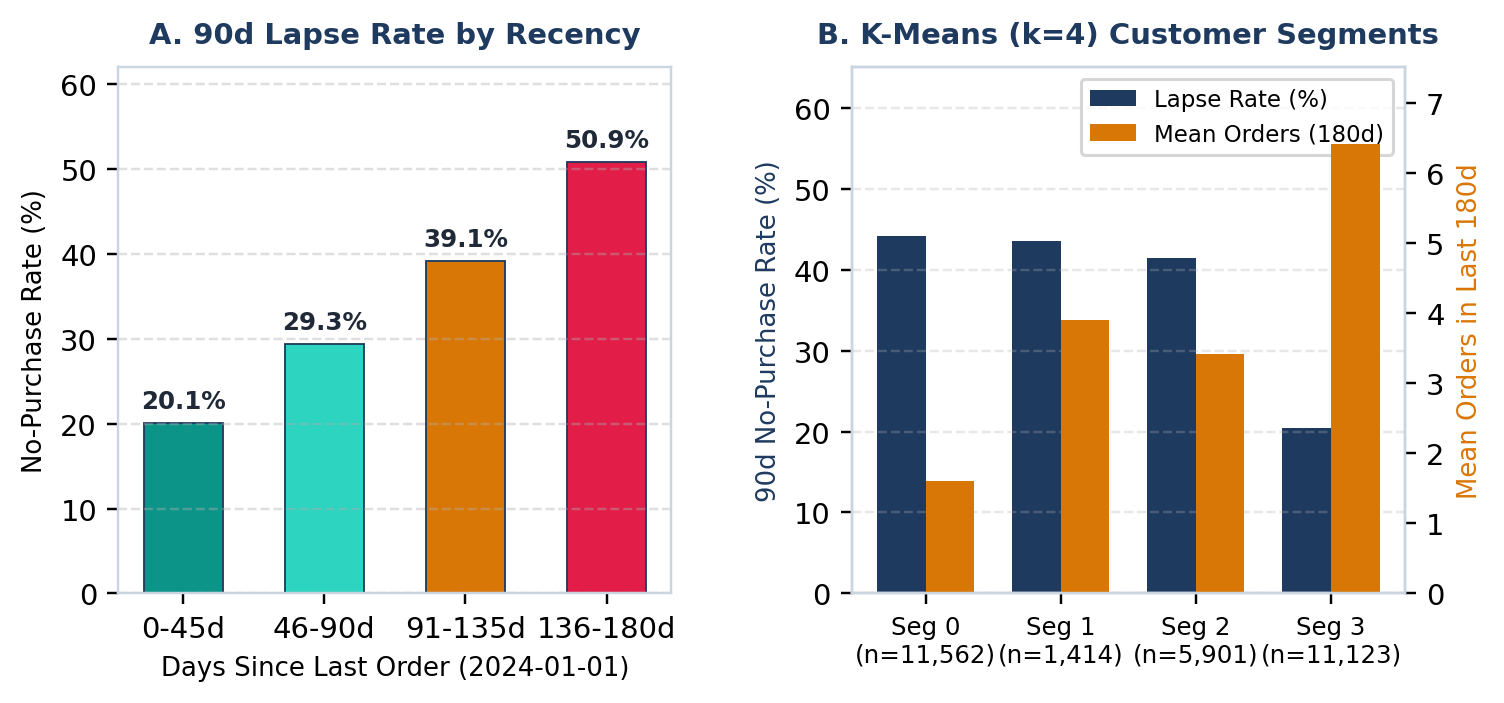

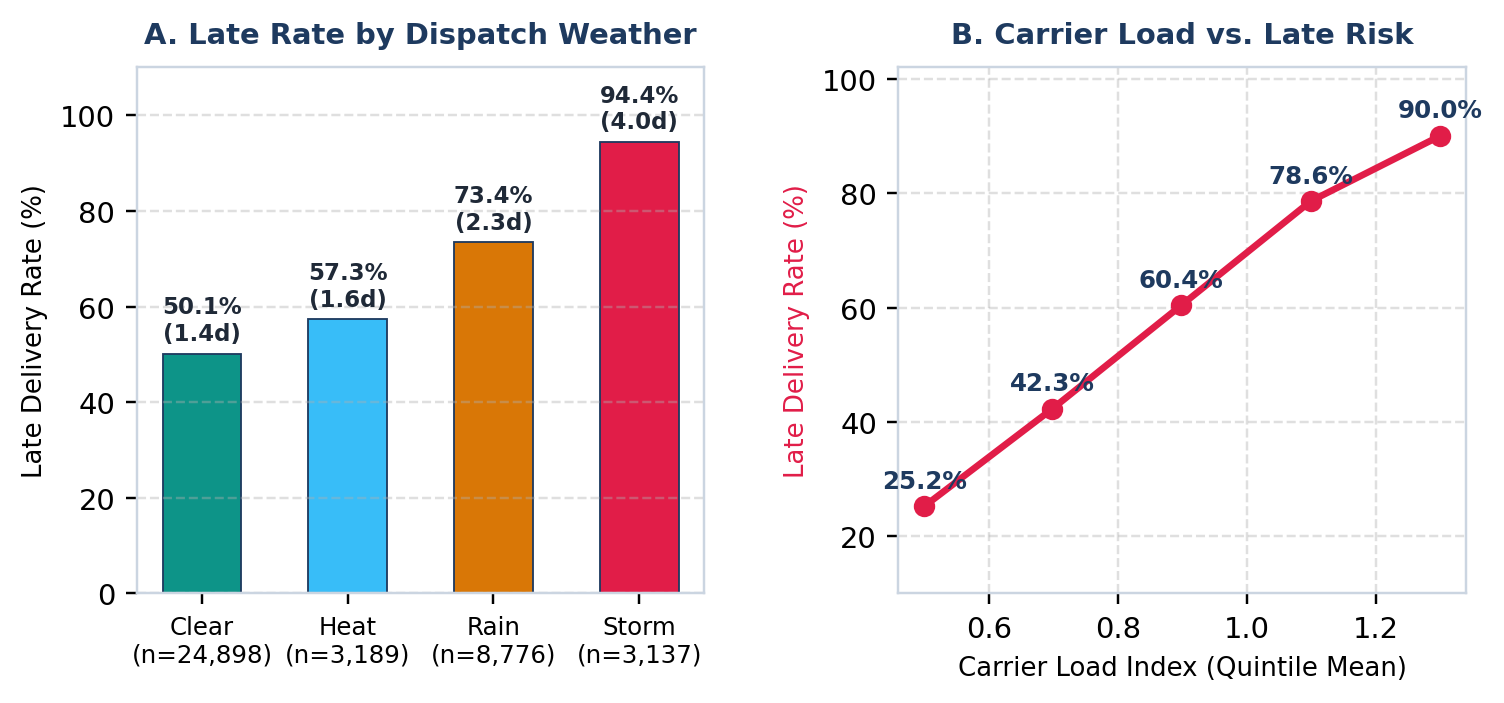

In [3]:
df_c = datasets["customer_retention"]
df_d = datasets["delivery_delay"]
df_r_tr = datasets["review_train"]
df_r_un = datasets["review_unlabeled"]
df_mql = datasets["olist_mql"]
df_cl = datasets["olist_closed"]

print("1. Customer Retention Logical Anomalies:")
print("   - days_since_last_order <= 180 but orders_last_180d == 0:", int(((df_c["days_since_last_order"] <= 180) & (df_c["orders_last_180d"] == 0)).sum()))
print("   - returns_last_180d > orders_last_180d:", int((df_c["returns_last_180d"] > df_c["orders_last_180d"]).sum()))
print("   - orders_last_180d == 0 but returns_last_180d > 0:", int(((df_c["orders_last_180d"] == 0) & (df_c["returns_last_180d"] > 0)).sum()))

print("\n2. Delivery Delay Physical Anomalies:")
print("   - actual_delivery_days < 0:", int((df_d["actual_delivery_days"] < 0).sum()), f"(min = {df_d['actual_delivery_days'].min()}d)")
print("   - actual_delivery_days <= 0:", int((df_d["actual_delivery_days"] <= 0).sum()))
print("   - Grace buffer rows (0 < delay_days <= 1.0 yet late_delivery == 0):", int(((df_d["delay_days"] > 0) & (df_d["delay_days"] <= 1.0) & (df_d["late_delivery"] == 0)).sum()))

print("\n3. NLP Review Template Collapse:")
print("   - Unique sentences in 20,000 train rows:", df_r_tr["review_text"].nunique())
print("   - Unique sentences in 2,000 unlabeled rows:", df_r_un["review_text"].nunique())
print("   - Exact template overlap:", len(set(df_r_tr["review_text"]).intersection(set(df_r_un["review_text"]))))

print("\n4. Marketing Funnel Missingness & Conversion:")
m_funnel = df_mql.merge(df_cl, on="mql_id", how="left")
print("   - Total MQLs:", len(m_funnel), "| Converted (won_date not null):", int(m_funnel["won_date"].notnull().sum()), f"({m_funnel['won_date'].notnull().mean()*100:.2f}%)")
print("   - Missing origin values in MQL table:", int(df_mql["origin"].isnull().sum()))
print("   - Structural nulls in closed_deals columns for unconverted leads:", int(m_funnel["business_segment"].isnull().sum()))


## 3. Time-Series Demand & Monthly Monitoring Drift Profiling
We inspect the 150-SKU $\times$ 730-day panel (`2023-01-01` to `2024-12-30`) and the 8-month covariate drift trajectories (`2024-01-01` to `2024-08-01`).


Daily Product Demand Summary:
   - Date span: 2023-01-01 to 2024-12-30 | Unique dates: 730 | Unique SKUs: 150
   - Mean units sold (No Promo vs Promo): {0: 18.1901, 1: 29.4169}
   - Mean units sold by Day of Week: {0: 18.73, 1: 21.55, 2: 22.32, 3: 20.27, 4: 17.03, 5: 15.01, 6: 15.67}

Monthly Feature Drift (% change Jan 2024 -> Aug 2024):
feature_name
feature_01    -19.04
feature_02     45.13
feature_03      5.11
feature_04    -28.81
feature_05    105.59
feature_06      9.57
feature_07     36.61
feature_08    124.41
feature_09     -3.95
feature_10    163.70


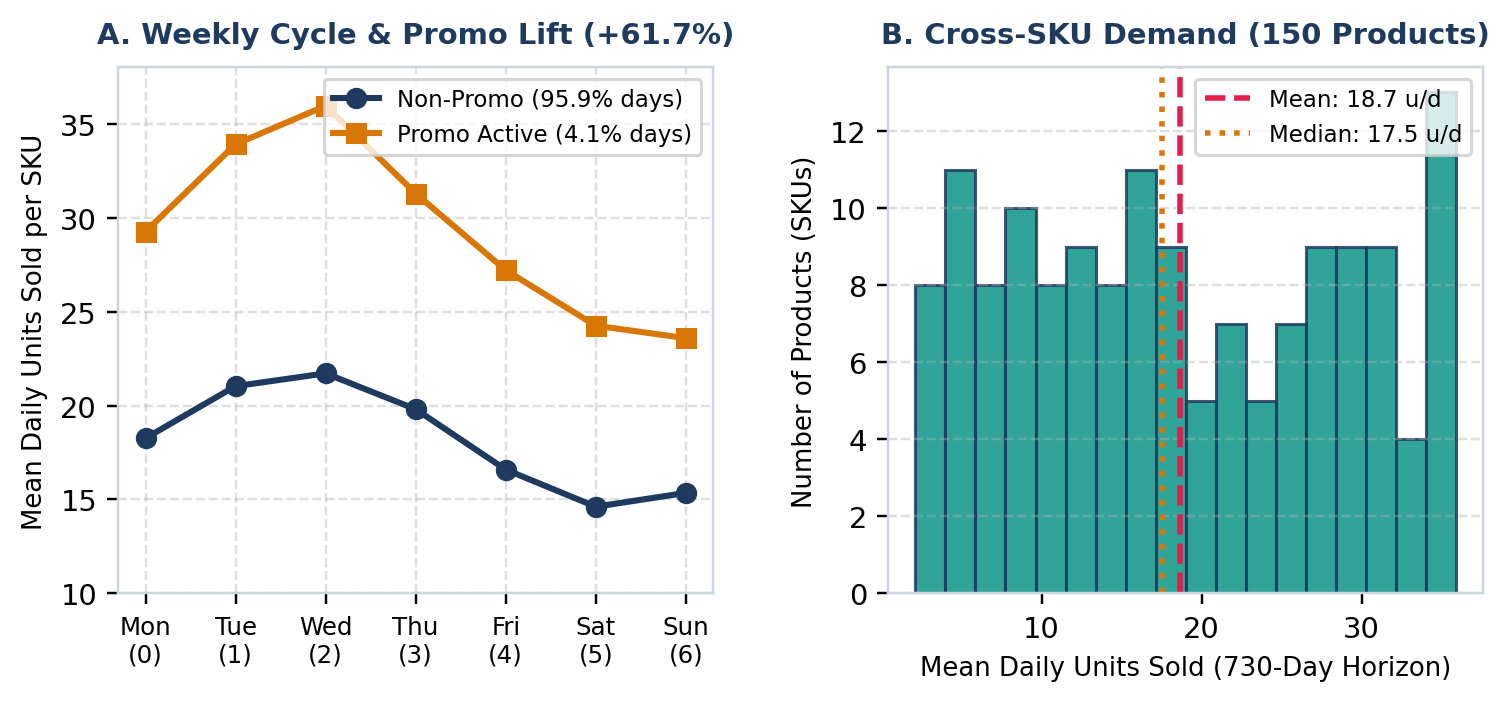

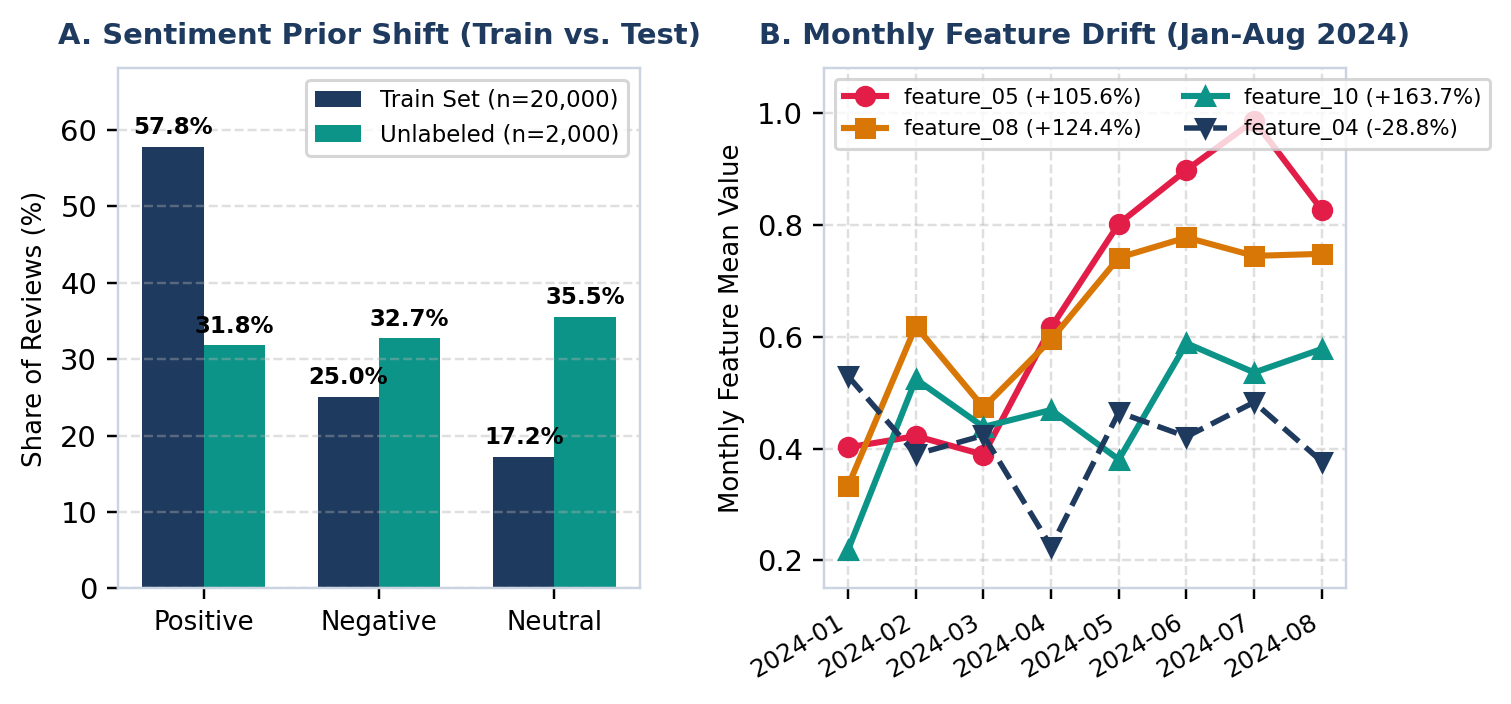

In [4]:
df_dem = datasets["daily_demand"]
df_mon = datasets["monitoring_drift"]

print("Daily Product Demand Summary:")
print("   - Date span:", df_dem["date"].min(), "to", df_dem["date"].max(), "| Unique dates:", df_dem["date"].nunique(), "| Unique SKUs:", df_dem["product_id"].nunique())
print("   - Mean units sold (No Promo vs Promo):", df_dem.groupby("promotion_flag")["units_sold"].mean().round(4).to_dict())
print("   - Mean units sold by Day of Week:", df_dem.groupby("day_of_week")["units_sold"].mean().round(2).to_dict())

piv_mon = df_mon.pivot(index="monitoring_month", columns="feature_name", values="mean_value")
drift_pct = ((piv_mon.iloc[-1] - piv_mon.iloc[0]) / piv_mon.iloc[0] * 100).round(2)
print("\nMonthly Feature Drift (% change Jan 2024 -> Aug 2024):")
print(drift_pct.to_string())
